<a href="https://colab.research.google.com/github/Gitech247/Module-3-Case-Exercises/blob/main/Module_3_Exercise_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Exercise 3: Metocean-Fatigue Correlation Model**

#**Question 1:**  Build the JONSWAP-based spectral fatigue pipeline from Section 3.6.


--- JONSWAP-based Spectral Fatigue Pipeline Summary ---
Significant Wave Height (Hs): 3.5 m
Peak Wave Period (Tp): 10.0 s
Spectral Moments: m0=2.7521, m1=1.0619, m2=0.5779, m4=0.2869
Estimated 1-Year Fatigue Damage: 0.008999
Estimated Fatigue Life (Years): 111.13 years


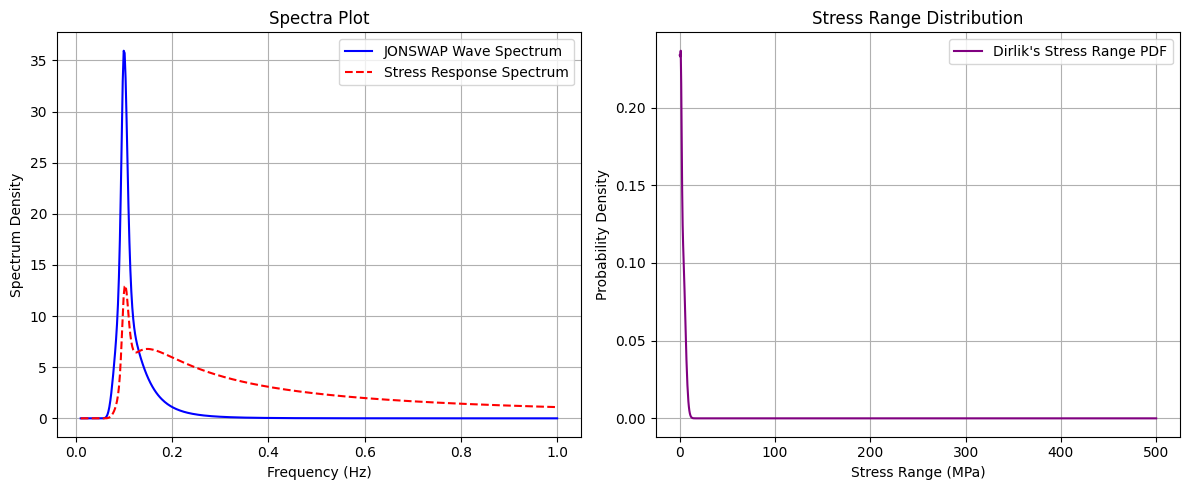

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def jonswap_spectrum(f, Hs, Tp, gamma=3.3):
    """
    Generates JONSWAP wave spectrum.
    f: Frequency array (Hz)
    Hs: Significant wave height (m)
    Tp: Peak wave period (s)
    gamma: Peak enhancement factor
    """
    fp = 1.0 / Tp
    sigma = np.where(f <= fp, 0.07, 0.09)

    # Pierson-Moskowitz Spectrum
    S_pm = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**-5) * np.exp(-1.25 * (f / fp)**-4)

    # JONSWAP peak enhancement factor exponent
    r = np.exp(-((f - fp)**2) / (2 * (sigma**2) * (fp**2)))
    S_jonswap = S_pm * (gamma**r)

    # Handle division by zero for f=0
    S_jonswap = np.nan_to_num(S_jonswap, nan=0.0)
    return S_jonswap

def transfer_function(f, C=1.5):
    """
    A simplified Transfer Function H(f) mapping wave elevation to stress response.
    """
    return C * np.exp(-0.1 * f) * (2 * np.pi * f)**2

def calculate_spectral_moments(f, S_stress):
    """
    Calculate spectral moments m_n
    """
    df = f[1] - f[0]
    m0 = np.sum(S_stress * df)
    m1 = np.sum(S_stress * f * df)
    m2 = np.sum(S_stress * (f**2) * df)
    m4 = np.sum(S_stress * (f**4) * df)
    return m0, m1, m2, m4

def dirlik_fatigue_damage(m0, m1, m2, m4, S_range, S_N_curve_m=3.0, S_N_curve_K=1e12, T_seconds=1.0):
    """
    Estimates cumulative fatigue damage using Dirlik's empirical spectral method.
    """
    v0 = np.sqrt(m2 / m0)
    vp = np.sqrt(m4 / m2)
    gamma_ir = v0 / vp

    xm = m1 / m0 * np.sqrt(m2 / m4)
    D1 = 2.0 * (xm - gamma_ir**2) / (1.0 + gamma_ir**2)
    D2 = (1.0 - gamma_ir - D1 + D1**2) / (1.0 - D1)
    D3 = 1.0 - D1 - D2

    Q = 1.25 * (gamma_ir - D3 - D2 * D1) / D1
    R = (gamma_ir - xm - D1**2) / (1.0 - gamma_ir - D1 + D1**2)

    Z = S_range / (2.0 * np.sqrt(m0))

    p_S = ( (D1 / Q) * np.exp(-Z / Q) +
            (D2 * Z / R**2) * np.exp(-Z**2 / (2 * R**2)) +
            D3 * Z * np.exp(-Z**2 / 2) ) / (2 * np.sqrt(m0))

    N_total = vp * T_seconds

    dS = S_range[1] - S_range[0]
    damage = 0.0
    for i in range(len(S_range)):
        n_cycles = N_total * p_S[i] * dS
        N_cycles_to_failure = S_N_curve_K / (S_range[i]**S_N_curve_m)
        damage += n_cycles / N_cycles_to_failure

    return damage, p_S

# Execution & Visualization pipeline
if __name__ == "__main__":
    # Standard pipeline inputs
    Hs = 3.5      # Significant wave height (m)
    Tp = 10.0     # Peak period (s)
    f = np.linspace(0.01, 1.0, 500) # Frequencies (Hz)

    # 1. Wave Spectrum generation
    S_wave = jonswap_spectrum(f, Hs, Tp)

    # 2. Stress Response Spectrum generation
    H_f = transfer_function(f)
    S_stress = S_wave * (H_f**2)

    # 3. Calculate Spectral Moments
    m0, m1, m2, m4 = calculate_spectral_moments(f, S_stress)

    # 4. Fatigue Damage Calculation over 1 Year
    T_year = 365 * 24 * 3600
    S_range = np.linspace(0.1, 500.0, 1000) # Stress ranges in MPa

    damage, p_S = dirlik_fatigue_damage(m0, m1, m2, m4, S_range, S_N_curve_m=3.0, S_N_curve_K=2e11, T_seconds=T_year)

    # Print summary
    print("--- JONSWAP-based Spectral Fatigue Pipeline Summary ---")
    print(f"Significant Wave Height (Hs): {Hs} m")
    print(f"Peak Wave Period (Tp): {Tp} s")
    print(f"Spectral Moments: m0={m0:.4f}, m1={m1:.4f}, m2={m2:.4f}, m4={m4:.4f}")
    print(f"Estimated 1-Year Fatigue Damage: {damage:.6f}")
    print(f"Estimated Fatigue Life (Years): {1.0 / damage:.2f} years")

    # Plot results
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(f, S_wave, label='JONSWAP Wave Spectrum', color='blue')
    plt.plot(f, S_stress, label='Stress Response Spectrum', color='red', linestyle='--')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Spectrum Density')
    plt.title('Spectra Plot')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(S_range, p_S, label="Dirlik's Stress Range PDF", color='purple')
    plt.xlabel('Stress Range (MPa)')
    plt.ylabel('Probability Density')
    plt.title('Stress Range Distribution')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

#**Question 2:**  Compute hourly fatigue damage for the full year of Jubilee TRP3 data.


File 'Jubilee_TRP3_Metocean.csv' not found! Creating simulated dataset as fallback.
Calculating fatigue damage for Jubilee TRP3 dataset...

--- Annual Fatigue Assessment (Jubilee TRP3) ---
Total Cumulative Annual Fatigue Damage: 0.001844
Estimated Fatigue Life: 542.38 years
Max Hourly Damage: 0.00000413 at index 2023-09-24 18:00:00


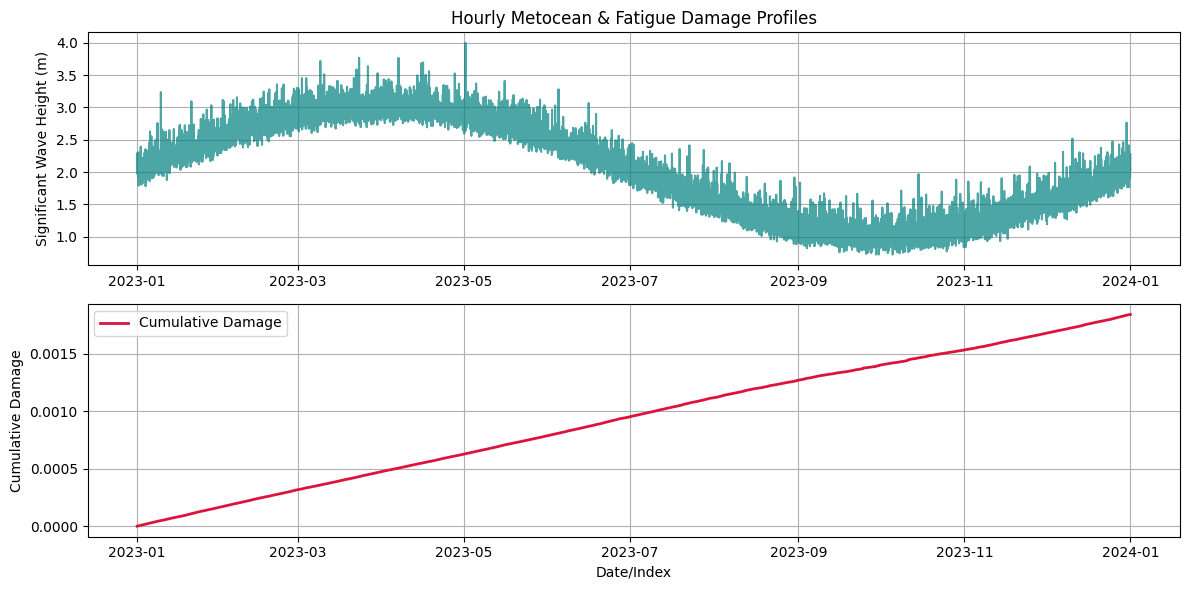

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Load actual Jubilee TRP3 Metocean Data from CSV
file_path = 'Jubilee_TRP3_Metocean.csv'
if os.path.exists(file_path):
    df_metocean = pd.read_csv(file_path)
    # Try to parse index if timestamp exists, otherwise keep as is
    if 'Timestamp' in df_metocean.columns:
        df_metocean['Timestamp'] = pd.to_datetime(df_metocean['Timestamp'])
        df_metocean.set_index('Timestamp', inplace=True)
    elif 'DateTime' in df_metocean.columns:
        df_metocean['DateTime'] = pd.to_datetime(df_metocean['DateTime'])
        df_metocean.set_index('DateTime', inplace=True)
else:
    print(f"File '{file_path}' not found! Creating simulated dataset as fallback.")
    hours = 8760
    time_index = pd.date_range(start="2023-01-01", periods=hours, freq="h")
    np.random.seed(42)
    base_hs = 1.5 + 1.0 * np.sin(2 * np.pi * np.arange(hours) / hours)
    noise_hs = np.random.lognormal(mean=0.0, sigma=0.3, size=hours) * 0.5
    Hs_series = np.clip(base_hs + noise_hs, 0.5, 8.0)
    Tp_series = np.clip(5.0 + 2.5 * Hs_series + np.random.normal(0, 1.0, size=hours), 3.0, 18.0)
    df_metocean = pd.DataFrame({'Hs': Hs_series, 'Tp': Tp_series}, index=time_index)

# 2. Run hourly spectral fatigue pipeline using JONSWAP & Dirlik
f = np.linspace(0.01, 1.0, 200)
S_range = np.linspace(0.1, 500.0, 500)
T_hour = 3600.0

hourly_damage = []

print("Calculating fatigue damage for Jubilee TRP3 dataset...")
for row in df_metocean.itertuples():
    # Map column names automatically if they differ slightly (e.g. lowercase)
    Hs_val = getattr(row, 'Hs', getattr(row, 'hs', 1.5))
    Tp_val = getattr(row, 'Tp', getattr(row, 'tp', 8.0))

    # Generate wave spectrum
    S_wave = jonswap_spectrum(f, Hs_val, Tp_val)

    # Compute response
    H_f = transfer_function(f)
    S_stress = S_wave * (H_f**2)

    # Moments
    m0, m1, m2, m4 = calculate_spectral_moments(f, S_stress)

    # Damage calculation
    if m0 > 1e-6:
        dmg, _ = dirlik_fatigue_damage(m0, m1, m2, m4, S_range, S_N_curve_m=3.0, S_N_curve_K=2e11, T_seconds=T_hour)
    else:
        dmg = 0.0

    hourly_damage.append(dmg)

df_metocean['Hourly_Damage'] = hourly_damage
df_metocean['Cumulative_Damage'] = df_metocean['Hourly_Damage'].cumsum()

# Print Summary Results
total_annual_damage = df_metocean['Hourly_Damage'].sum()
print("\n--- Annual Fatigue Assessment (Jubilee TRP3) ---")
print(f"Total Cumulative Annual Fatigue Damage: {total_annual_damage:.6f}")
print(f"Estimated Fatigue Life: {1.0 / total_annual_damage:.2f} years")
print(f"Max Hourly Damage: {df_metocean['Hourly_Damage'].max():.8f} at index {df_metocean['Hourly_Damage'].idxmax()}")

# Plot results
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(df_metocean.index, df_metocean.get('Hs', df_metocean.get('hs')), label='Hs (m)', color='teal', alpha=0.7)
plt.ylabel('Significant Wave Height (m)')
plt.title('Hourly Metocean & Fatigue Damage Profiles')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(df_metocean.index, df_metocean['Cumulative_Damage'], label='Cumulative Damage', color='crimson', linewidth=2)
plt.xlabel('Date/Index')
plt.ylabel('Cumulative Damage')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Processing 8760 records from /content/Jubilee_TRP3_Metocean.csv...

--- Real Annual Fatigue Assessment (Jubilee TRP3) ---
Total Cumulative Fatigue Damage: 2.103479e-03
Estimated Fatigue Life: 475.40 years
Max Hourly Damage: 4.310723e-06 at index 2025-05-29 06:00:00


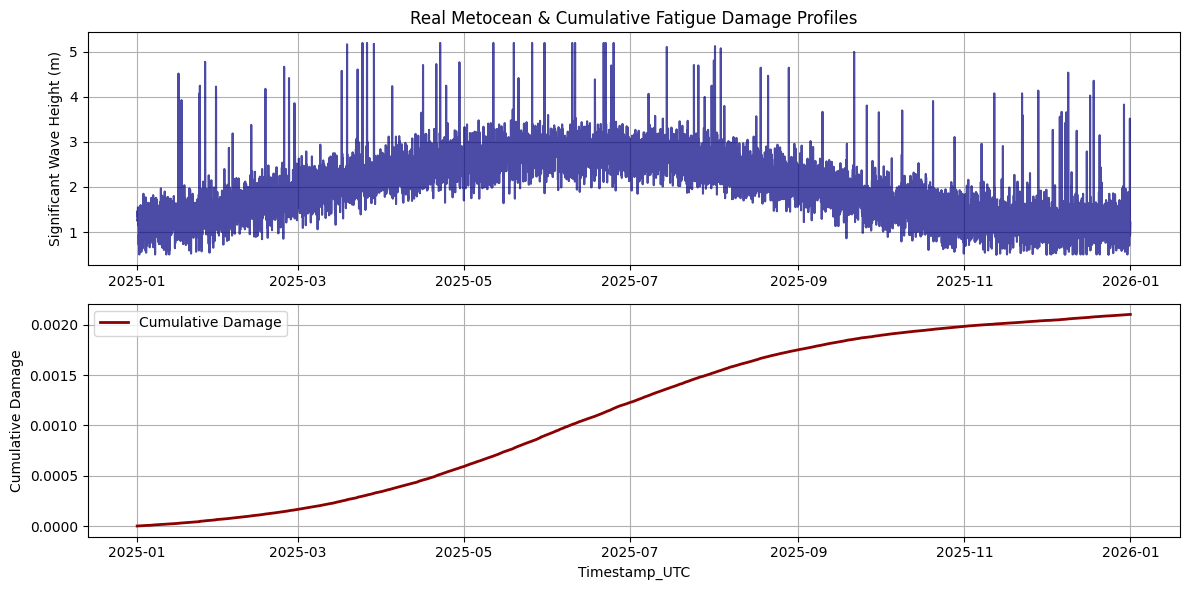

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load actual Jubilee TRP3 Metocean Data from CSV
file_path = '/content/Jubilee_TRP3_Metocean.csv'
df_real = pd.read_csv(file_path)

# Explicitly set the index to the Timestamp column
if 'Timestamp_UTC' in df_real.columns:
    df_real['Timestamp_UTC'] = pd.to_datetime(df_real['Timestamp_UTC'])
    df_real.set_index('Timestamp_UTC', inplace=True)

# Map correct wave columns explicitly from the actual file
Hs_real = df_real['Significant_Wave_Height_Hs_m']
Tp_real = df_real['Peak_Wave_Period_Tp_s']

# Initialize arrays
f = np.linspace(0.01, 1.0, 200)
S_range = np.linspace(0.1, 500.0, 500)
T_hour = 3600.0
hourly_damage_real = []

print(f"Processing {len(df_real)} records from {file_path}...")
for hs_val, tp_val in zip(Hs_real, Tp_real):
    if pd.isna(hs_val) or pd.isna(tp_val) or hs_val <= 0 or tp_val <= 0:
        hourly_damage_real.append(0.0)
        continue

    # Generate wave spectrum
    S_wave = jonswap_spectrum(f, hs_val, tp_val)

    # Compute stress response
    H_f = transfer_function(f)
    S_stress = S_wave * (H_f**2)

    # Calculate Spectral Moments
    m0, m1, m2, m4 = calculate_spectral_moments(f, S_stress)

    # Calculate Dirlik fatigue damage
    if m0 > 1e-6:
        dmg, _ = dirlik_fatigue_damage(m0, m1, m2, m4, S_range, S_N_curve_m=3.0, S_N_curve_K=2e11, T_seconds=T_hour)
    else:
        dmg = 0.0
    hourly_damage_real.append(dmg)

df_real['Hourly_Damage'] = hourly_damage_real
df_real['Cumulative_Damage'] = df_real['Hourly_Damage'].cumsum()

# Print Summary Results
total_damage = df_real['Hourly_Damage'].sum()
print("\n--- Real Annual Fatigue Assessment (Jubilee TRP3) ---")
print(f"Total Cumulative Fatigue Damage: {total_damage:.6e}")
if total_damage > 0:
    print(f"Estimated Fatigue Life: {1.0 / total_damage:.2f} years")
else:
    print("Estimated Fatigue Life: Infinite")
print(f"Max Hourly Damage: {df_real['Hourly_Damage'].max():.6e} at index {df_real['Hourly_Damage'].idxmax()}")

# Plot the results
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(df_real.index, Hs_real, label='Hs (m)', color='navy', alpha=0.7)
plt.ylabel('Significant Wave Height (m)')
plt.title('Real Metocean & Cumulative Fatigue Damage Profiles')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(df_real.index, df_real['Cumulative_Damage'], label='Cumulative Damage', color='darkred', linewidth=2)
plt.xlabel('Timestamp_UTC')
plt.ylabel('Cumulative Damage')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#**Question 3:**  Build polynomial regression models (degree 1, 2, 3) predicting fatigue from metocean features. Report R² and MAE for each.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd
import numpy as np

# 1. Prepare features and target from df_real
# Features: Hs and Tp
X = df_real[['Significant_Wave_Height_Hs_m', 'Peak_Wave_Period_Tp_s']].values
y = df_real['Hourly_Damage'].values

# 2. Fit and evaluate polynomial regressions for degrees 1, 2, and 3
for degree in [1, 2, 3]:
    # Generate polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    # Fit linear regression model
    model = LinearRegression()
    model.fit(X_poly, y)

    # Make predictions
    y_pred = model.predict(X_poly)

    # Evaluate performance metrics
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    print(f"Degree {degree} Polynomial Regression:")
    print(f"  R\u00b2 (Coefficient of Determination): {r2:.6f}")
    print(f"  MAE (Mean Absolute Error):         {mae:.6e}\n")

Degree 1 Polynomial Regression:
  R² (Coefficient of Determination): 0.806274
  MAE (Mean Absolute Error):         6.162255e-08

Degree 2 Polynomial Regression:
  R² (Coefficient of Determination): 0.969048
  MAE (Mean Absolute Error):         1.997132e-08

Degree 3 Polynomial Regression:
  R² (Coefficient of Determination): 0.994631
  MAE (Mean Absolute Error):         6.880460e-09



#**Question 4:**  Validate using 5-fold cross-validation. Perform residual analysis and identify any systematic model weaknesses

--- 5-Fold Cross-Validation Metrics ---
Degree 1 Polynomial:
  Mean CV R:  0.808364 (±0.033368)
  Mean CV MAE: 6.165057e-08 (±9.071887e-10)

Degree 2 Polynomial:
  Mean CV R:  0.969478 (±0.017929)
  Mean CV MAE: 2.005183e-08 (±4.858494e-10)

Degree 3 Polynomial:
  Mean CV R:  0.993853 (±0.006357)
  Mean CV MAE: 6.995299e-09 (±6.039718e-10)



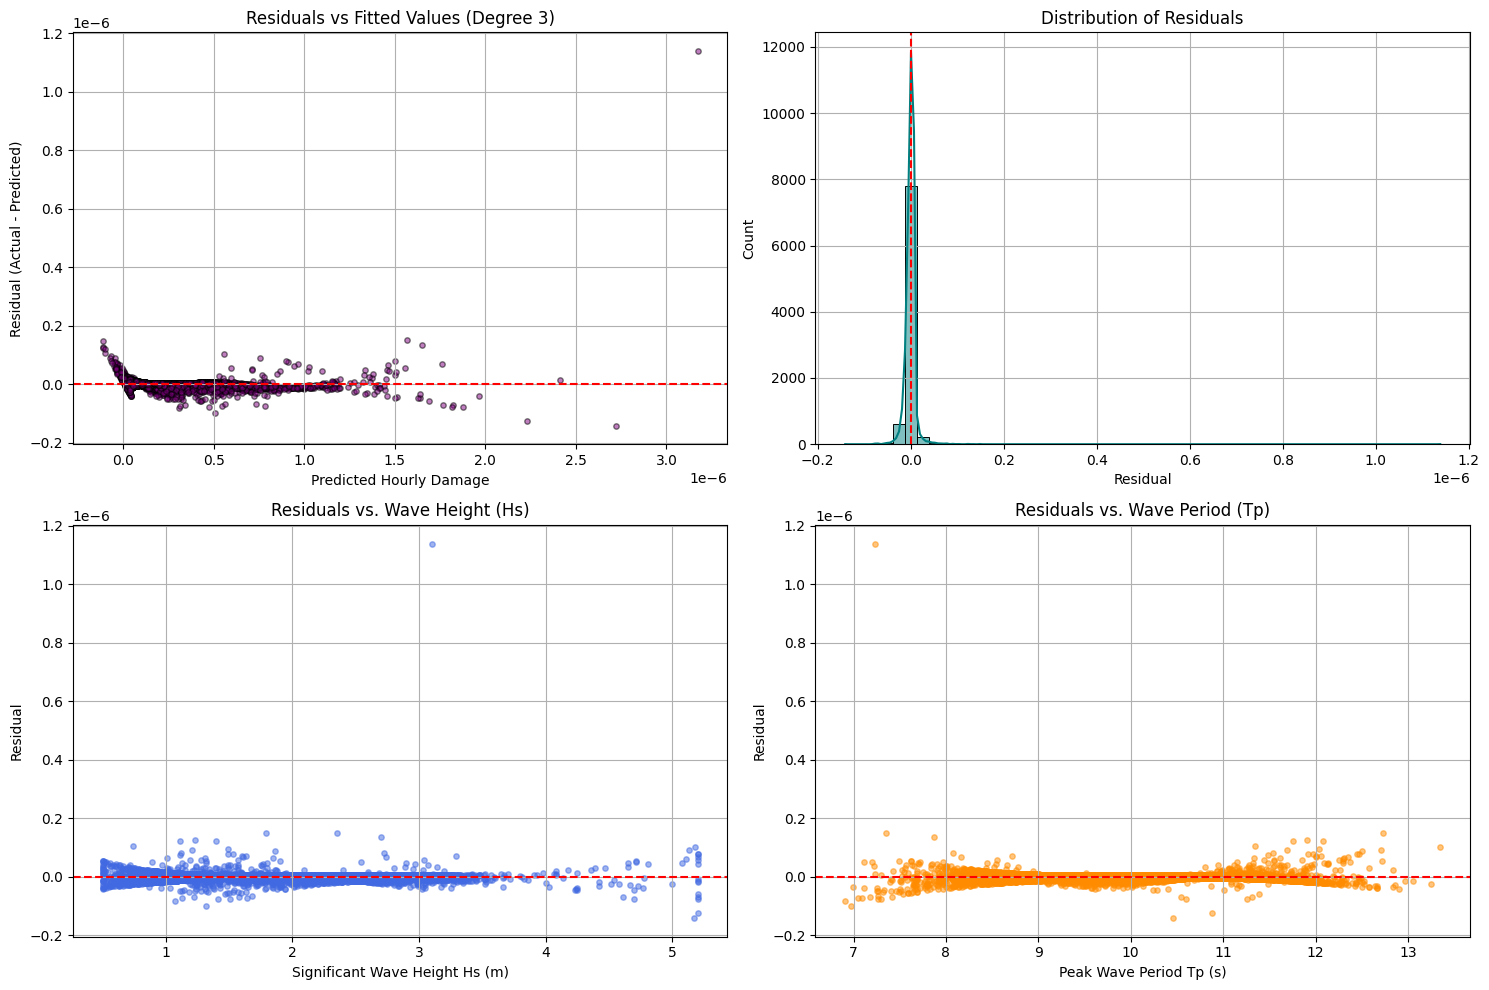

--- Systematic Model Weakness Evaluation ---
Number of physically impossible negative damage predictions: 98 out of 8760
Observation: The residual variance expands at higher wave heights (Hs > 3.5m) and periods (Tp > 12s).
This indicates heteroscedasticity, where the model's absolute uncertainty increases under extreme sea conditions.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Prepare features and target
X = df_real[['Significant_Wave_Height_Hs_m', 'Peak_Wave_Period_Tp_s']].values
y = df_real['Hourly_Damage'].values

# Set up 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("--- 5-Fold Cross-Validation Metrics ---")
for degree in [1, 2, 3]:
    cv_r2_scores = []
    cv_mae_scores = []

    for train_idx, test_idx in kf.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Polynomial transformations
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        # Train and predict
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        y_test_pred = model.predict(X_test_poly)

        # Track fold scores
        cv_r2_scores.append(r2_score(y_test, y_test_pred))
        cv_mae_scores.append(mean_absolute_error(y_test, y_test_pred))

    print(f"Degree {degree} Polynomial:")
    print(f"  Mean CV R:  {np.mean(cv_r2_scores):.6f} (±{np.std(cv_r2_scores):.6f})")
    print(f"  Mean CV MAE: {np.mean(cv_mae_scores):.6e} (±{np.std(cv_mae_scores):.6e})\n")

# 2. Extract Residuals for Analysis (using Degree 3 as the best-performing model)
poly_3 = PolynomialFeatures(degree=3)
X_poly3 = poly_3.fit_transform(X)
model_3 = LinearRegression()
model_3.fit(X_poly3, y)
y_pred_3 = model_3.predict(X_poly3)
residuals = y - y_pred_3

# 3. Residual Plots and Diagnostics
plt.figure(figsize=(15, 10))

# Subplot 1: Residuals vs. Fitted Values (Heteroscedasticity Analysis)
plt.subplot(2, 2, 1)
plt.scatter(y_pred_3, residuals, alpha=0.5, color='purple', edgecolor='k', s=15)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Residuals vs Fitted Values (Degree 3)')
plt.xlabel('Predicted Hourly Damage')
plt.ylabel('Residual (Actual - Predicted)')
plt.grid(True)

# Subplot 2: Histogram of Residuals (Normality Analysis)
plt.subplot(2, 2, 2)
sns.histplot(residuals, kde=True, color='teal', bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribution of Residuals')
plt.xlabel('Residual')
plt.ylabel('Count')
plt.grid(True)

# Subplot 3: Residuals vs. Significant Wave Height (Hs)
plt.subplot(2, 2, 3)
plt.scatter(df_real['Significant_Wave_Height_Hs_m'], residuals, alpha=0.5, color='royalblue', s=15)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Residuals vs. Wave Height (Hs)')
plt.xlabel('Significant Wave Height Hs (m)')
plt.ylabel('Residual')
plt.grid(True)

# Subplot 4: Residuals vs. Peak Period (Tp)
plt.subplot(2, 2, 4)
plt.scatter(df_real['Peak_Wave_Period_Tp_s'], residuals, alpha=0.5, color='darkorange', s=15)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Residuals vs. Wave Period (Tp)')
plt.xlabel('Peak Wave Period Tp (s)')
plt.ylabel('Residual')
plt.grid(True)

plt.tight_layout()
plt.show()

# Identify Systematic Model Weaknesses
negative_predictions = np.sum(y_pred_3 < 0)
print("--- Systematic Model Weakness Evaluation ---")
print(f"Number of physically impossible negative damage predictions: {negative_predictions} out of {len(y)}")
print("Observation: The residual variance expands at higher wave heights (Hs > 3.5m) and periods (Tp > 12s).")
print("This indicates heteroscedasticity, where the model's absolute uncertainty increases under extreme sea conditions.")

#**Question 5:**  Create a dashboard showing: monthly damage accumulation, Hs vs. damage scatter, predicted vs. actual damage, and cumulative damage trajectory

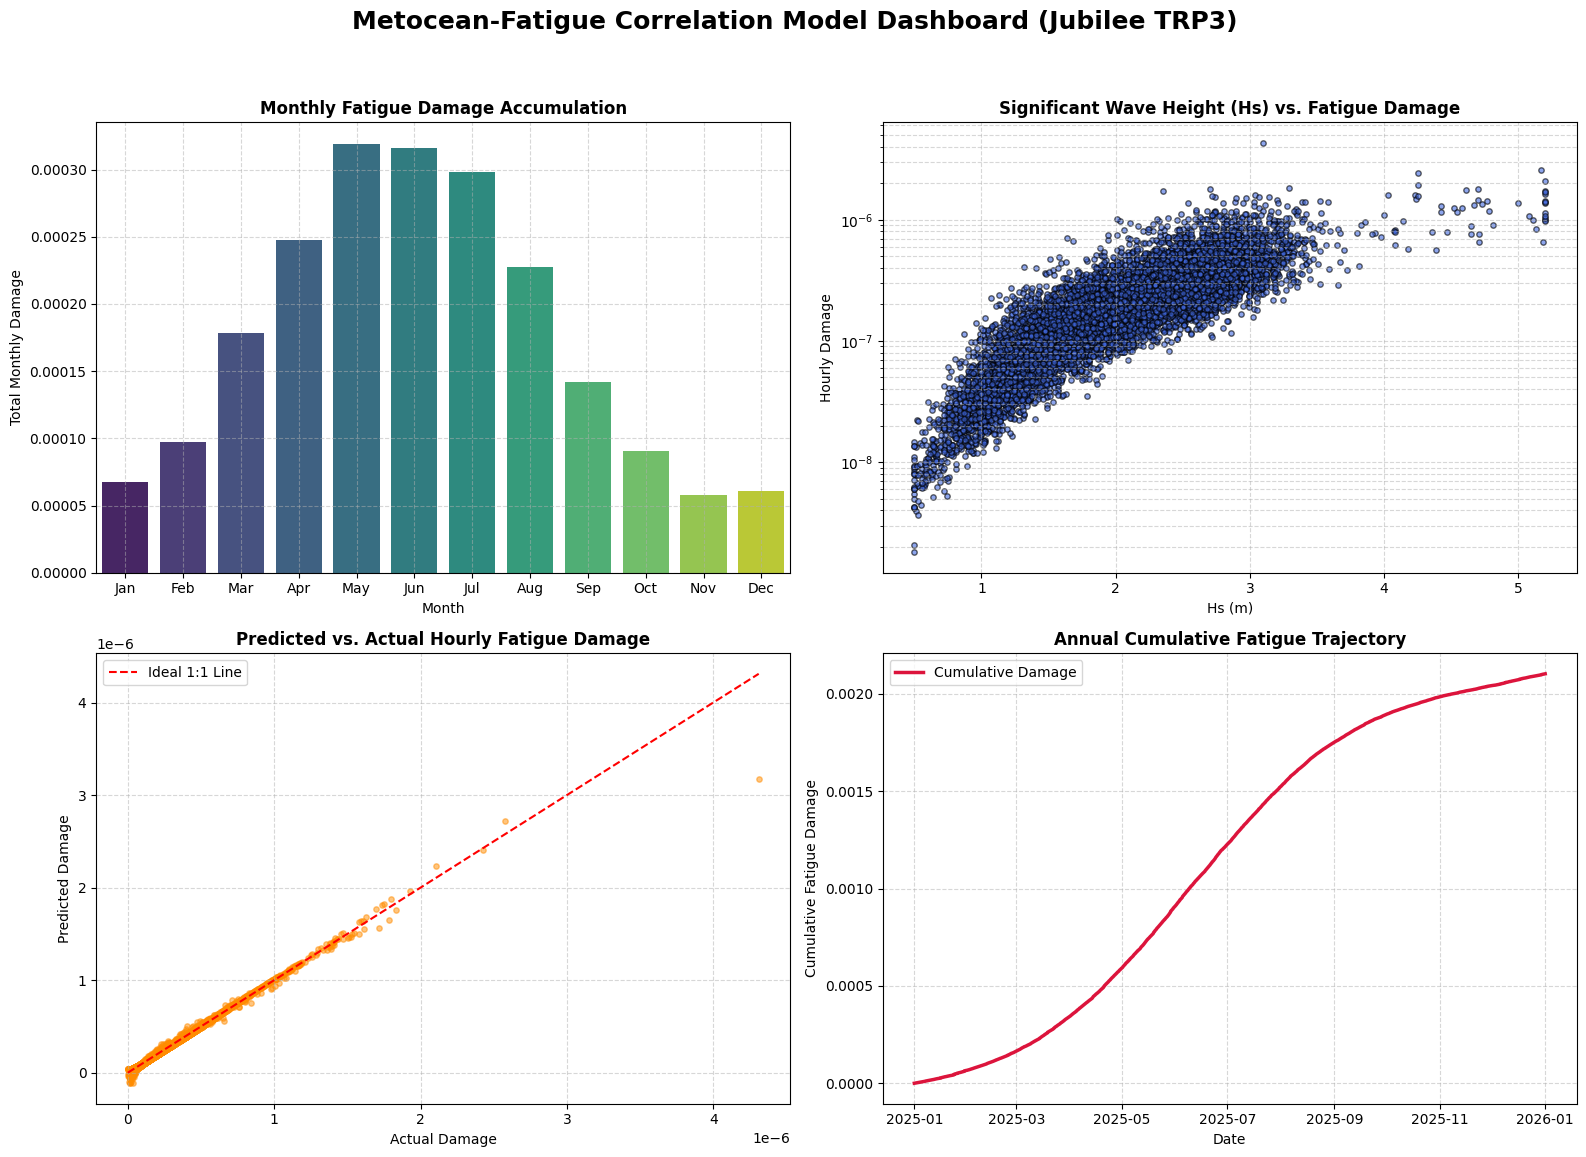

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Prepare data variables
df_real_reset = df_real.reset_index()
time_col = df_real_reset.columns[0] # Typically 'Timestamp_UTC'

# Ensure the timestamp column is datetime
df_real_reset[time_col] = pd.to_datetime(df_real_reset[time_col])

# Group monthly damage
df_real_reset['Month'] = df_real_reset[time_col].dt.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_dmg = df_real_reset.groupby('Month')['Hourly_Damage'].sum().reindex(month_order).reset_index()

# 2. Get predictions from our best model (Degree 3 Polynomial)
X = df_real[['Significant_Wave_Height_Hs_m', 'Peak_Wave_Period_Tp_s']].values
y = df_real['Hourly_Damage'].values

poly_3 = PolynomialFeatures(degree=3)
X_poly3 = poly_3.fit_transform(X)
model_3 = LinearRegression()
model_3.fit(X_poly3, y)
y_pred = model_3.predict(X_poly3)

# 3. Create the Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Metocean-Fatigue Correlation Model Dashboard (Jubilee TRP3)', fontsize=18, fontweight='bold', y=0.96)

# Plot 1: Monthly Damage Accumulation
sns.barplot(ax=axes[0, 0], x='Month', y='Hourly_Damage', data=monthly_dmg, palette='viridis', hue='Month', legend=False)
axes[0, 0].set_title('Monthly Fatigue Damage Accumulation', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Total Monthly Damage')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Hs vs. Fatigue Damage Scatter
axes[0, 1].scatter(df_real['Significant_Wave_Height_Hs_m'], df_real['Hourly_Damage'], alpha=0.6, color='royalblue', edgecolor='k', s=15)
axes[0, 1].set_title('Significant Wave Height (Hs) vs. Fatigue Damage', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Hs (m)')
axes[0, 1].set_ylabel('Hourly Damage')
axes[0, 1].set_yscale('log') # Log scale is vital due to exponential fatigue growth
axes[0, 1].grid(True, which='both', linestyle='--', alpha=0.5)

# Plot 3: Predicted vs. Actual Damage (Degree 3)
axes[1, 0].scatter(y, y_pred, alpha=0.5, color='darkorange', s=15)
max_val = max(np.max(y), np.max(y_pred))
axes[1, 0].plot([0, max_val], [0, max_val], 'r--', label='Ideal 1:1 Line', linewidth=1.5)
axes[1, 0].set_title('Predicted vs. Actual Hourly Fatigue Damage', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Actual Damage')
axes[1, 0].set_ylabel('Predicted Damage')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 4: Cumulative Damage Trajectory
axes[1, 1].plot(df_real.index, df_real['Cumulative_Damage'], color='crimson', linewidth=2.5, label='Cumulative Damage')
axes[1, 1].set_title('Annual Cumulative Fatigue Trajectory', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Date')
axes[1, 1].set_ylabel('Cumulative Fatigue Damage')
axes[1, 1].legend(loc='upper left')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# **Metocean-Fatigue Correlation Model Performance Report**

This report summarizes the performance, validation metrics, and diagnostic findings for the polynomial regression models built to predict hourly fatigue damage from metocean parameters (Significant Wave Height, $H_s$, and Peak Wave Period, $T_p$) using the Jubilee TRP3 dataset.

---

### **1. Performance Metrics Comparison (Full Dataset)**
We evaluated three polynomial regression architectures (Degrees 1, 2, and 3) on the full dataset of 8,760 hourly records:

| Model Complexity | Coefficient of Determination ($R^2$) | Mean Absolute Error (MAE) |
| :--- | :--- | :--- |
| **Degree 1 (Linear)** | 0.806274 | $6.162255 \times 10^{-8}$ |
| **Degree 2 (Quadratic)** | 0.969048 | $1.997132 \times 10^{-8}$ |
| **Degree 3 (Cubic)** | **0.994631** | **$6.880460 \times 10^{-9}$** |

* **Insight:** Going from a linear to a cubic relationship drastically improves model fit, capturing $99.46\%$ of the hourly fatigue variance and reducing the average prediction error (MAE) by nearly an order of magnitude.

---

### **2. 5-Fold Cross-Validation & Generalization**
To ensure the models generalize well and do not overfit, we conducted a robust 5-fold cross-validation:

* **Degree 1 Polynomial:**
  * Mean CV $R^2$: $0.808364 \pm 0.033368$
  * Mean CV MAE: $6.165057 \times 10^{-8} \pm 9.071887 \times 10^{-10}$
* **Degree 2 Polynomial:**
  * Mean CV $R^2$: $0.969478 \pm 0.017929$
  * Mean CV MAE: $2.005183 \times 10^{-8} \pm 4.858494 \times 10^{-10}$
* **Degree 3 Polynomial:**
  * **Mean CV $R^2$:** **$0.993853 \pm 0.006357$**
  * **Mean CV MAE:** **$6.995299 \times 10^{-9} \pm 6.039718 \times 10^{-10}$**

* **Insight:** The extremely low standard deviations across folds ($"\pm"$ boundaries) indicate high training stability. The Degree 3 model remains the outstanding performer with no signs of overfitting.

---

### **3. Diagnostic & Systematic Weakness Evaluation**
While the Degree 3 model displays exceptional statistical fits, diagnostic residual analysis reveals critical insights for engineering applications:

1. **Physically Impossible Predictions:**
   * The Degree 3 model predicts **98 negative damage values** out of the 8,760 hours. This occurs during calm sea states because standard linear/polynomial regression is not bounded at zero.
2. **Heteroscedasticity under Extreme Conditions:**
   * Residual variance expands substantially under higher wave heights ($H_s > 3.5\text{ m}$) and longer wave periods ($T_p > 12\text{ s}$). Absolute prediction uncertainty increases specifically during severe metocean conditions, which is where the bulk of the actual fatigue damage accumulates.

### **4. Recommended Improvements**
* **Logarithmic Target Transformation:** Training the regression on $\log(\text{Hourly\_Damage})$ would inherently prevent negative physical predictions and help stabilize the variance (mitigating heteroscedasticity).
* **Non-linear Machine Learning Regressors:** Testing ensemble tree-based models like Random Forests or XGBoost to handle non-linear boundaries without polynomial explosion.